# Figure 2 — publication layout

Rebuilt in code from `Figure2.png`, the hand-assembled reference. Every panel comes
from `Figure2.ipynb`; where a panel had several versions, this uses **version A**.

| panel | content | source panel in `Figure2.ipynb` |
|-------|---------|--------------------------------|
| **a** | genes whose factors match GENCODE transcripts | `torino_gene_annot_pct` |
| **b** | isoform classes vs the APPRIS principal transcript | `upset_isoforms` |
| **c** | retained introns along the gene body, Gencode vs Torino | `gencode_v_torino_introns` |
| **d** | *SRSF3* long reads per isoform + loadings | `SRSF3.long_reads` (A), `SRSF3.long_reads_loadings` |
| **e** | long-read support for *SRSF3* polyadenylation sites | `UTRs_SRSF3` |
| **f** | *SYNGR1* long reads per isoform + loadings | `SYNGR1.long_reads` (A), `SYNGR1.long_reads_loadings` |

Panels read A→F left-to-right, top-to-bottom: **e leads the bottom row and f follows
it**, which works because the two blocks are 60 and 114 mm wide and the row is 178 mm.
F is D's block translated to the right margin (`F_X0`), so the two long-read panels
keep identical internal geometry.

The reference's `SRSF3.gencode` and `GTEx.LongRead_vs_ShorRead.Correlation` panels
are not part of this figure.

**How to re-direct it.** The page is planned in millimetres from the top-left
through `rect()` in the layout cell, and `PAGE_H` is *derived* from the vertical
plan rather than typed in. A few single constants carry most of the layout:

* `LR_H` — the track-block height shared by **d** and **f** (35.2 mm); `LR_RIGHT_W`
  is tied to it so each loadings scatter is square; changing it compresses
  both without touching any width.
* `LR_TRACK_W` / `LR_RIGHT_W` — the two halves of D and F, again shared.
* **c** is pinned to the left block: its heatmaps end where D's tracks end
  (`C_PLOT_H`). **e** starts on F's title and content (`E_BAND`, `E_TOP`).
* `A_STYLE` switches panel A between the dumbbell (`'dots'`) and the reference's
  annotated heatmap (`'table'`); both keep the same overall width, so **b** never
  moves.

## Setup and shared style

In [1]:
"""Figure 2 -- publication layout.

Rebuilt in code from `Figure2.png`, the hand-assembled reference. Panels come
from `Figure2.ipynb`; where a panel had several versions, this uses **version A**.

The page is planned in millimetres from the top-left through `rect()`; `PAGE_H`
is derived by summing the vertical plan, not typed in.
"""
import os
import pickle
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

os.chdir('/project2/yangili1/cfbuenabadn/torino_paper/analysis')
sys.path.append('/project2/yangili1/cfbuenabadn/torino/scripts')
sys.path.append('/project2/yangili1/cfbuenabadn/torino_paper/code/scripts')
sys.path.append('/project2/yangili1/cfbuenabadn/torino_paper/analysis')
sys.path.append('/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure2')

import torino_plots
import LongReadPlots
from LongReadPlots import (
    adjust_fractions,
    group_transcripts,
    make_isoform_match_bed,
    plot_isoform_annotations_and_long_reads_single_ax,
)

MM = 1 / 25.4

# -- Typography (Nature Genetics: sans-serif, 5-7 pt, rules <= 0.5 pt) --
FS_BASE = 6.0      # tick labels
FS_LABEL = 6.5     # axis labels
FS_TITLE = 7.0     # panel titles
FS_SMALL = 5.5     # keys, in-panel annotations
FS_TINY = 5.0      # coverage callouts
FS_PANEL = 8.0     # panel letters
PANEL_LETTERS = 'abcdef'   # lower case, as Figure 1 uses (reference had caps)

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': FS_BASE,
    'axes.linewidth': 0.4,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.major.size': 1.6,
    'ytick.major.size': 1.6,
    'xtick.labelsize': FS_BASE,
    'ytick.labelsize': FS_BASE,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'savefig.dpi': 400,
})

# -- Shared colours -----------------------------------------------------
BRAIN_C = '#EEEE00'        # Brain Frontal Cortex (BA9)
MUSCLE_C = '#7A67EE'       # Muscle Skeletal (MS)
ISO_COLORS = sns.color_palette('tab10')     # isoform k -> ISO_COLORS[k]
TORINO_C = 'navy'          # Torino models and callouts
GENCODE_C = 'tab:red'      # Gencode models and callouts
MISSING_C = 'tab:gray'
SPREAD_C = 'black'         # median / range marks over the read stacks

# A title is either a plain string (may contain a newline) or a list of
# (text, italic) runs drawn side by side. Runs exist so that gene names stay
# italic *without* mathtext: matplotlib renders any $...$ label as one tspan
# carrying a per-character x list, which is what makes the glyphs pile up when
# the label is retyped in Inkscape.
PANEL_TITLES = {
    'A': 'Genes whose factors match\nGENCODE transcripts',
    'B': 'Isoform classes relative to the\nAPPRIS principal transcript',
    'C': 'Retained introns along the gene body',
    'D': [('Long reads validate ', False), ('SRSF3', True), (' isoforms', False)],
    'E': [[('Long-read support for ', False), ('SRSF3', True)],
          [('polyadenylation sites', False)]],
    'F': [('Long reads validate ', False), ('SYNGR1', True), (' isoforms', False)],
}


def title_lines(t):
    """Normalise a title to a list of lines, each a list of (text, italic)."""
    if isinstance(t, str):
        return [[(ln, False)] for ln in t.split('\n')]
    return [t] if isinstance(t[0], tuple) else list(t)


def title_text(t):
    """The widest line of a title as plain text, for fitting."""
    return max((''.join(r for r, _ in line) for line in title_lines(t)), key=len)

custom-made modules


## Data

Pre-computed by `prepare_figure2_data.py`; rerun that on a compute node to refresh
`figure_data/`. Nothing here computes — the notebook only unpickles.

In [2]:
DATA_DIR = '../notebooks/Figure2/figure_data'


def load_pkl(name):
    with open(os.path.join(DATA_DIR, name), 'rb') as f:
        return pickle.load(f)


gene_pct_df = load_pkl('gene_pct_df.pkl')
_gc = load_pkl('gene_count_df.pkl')
gene_num_df, gene_den_df = _gc['num_df'], _gc['den_df']
APPRIS_LEN_LO, APPRIS_LEN_HI = int(_gc['appris_len_lo']), int(_gc['appris_len_hi'])

df_upset = load_pkl('df_upset.pkl')

_im = load_pkl('intron_matrices.pkl')
gencode_X, torino_X = _im['gencode_X'], _im['torino_X']

_utr = load_pkl('utrs_srsf3.pkl')
coverage_data = _utr['coverage_data']
utr_start, utr_end = _utr['start'], _utr['end']
ref_chain_iso_srsf3 = _utr['ref_chain_iso_srsf3']
gencode_iso_plot_relevant = _utr['gencode_iso_plot_relevant']

_lr = load_pkl('long_reads_shared.pkl')
isoform_bed = _lr['isoform_bed']
lr_table_str = _lr['lr_table_str']
annot_lr = _lr['annot_lr']
human_EL = _lr['human_EL']
human_metadata = _lr['human_metadata']

_s3 = load_pkl('srsf3_long_reads.pkl')
_sy = load_pkl('syngr1_long_reads.pkl')

# The efficiency filter drops SRSF3.isoform_1, so its five tracks are
# isoform_2..6; both the reference and this figure renumber them 1..5.
#
# NOTE: the reference swaps SRSF3's 3rd and 4th columns relative to version A's
# order (`list(isoform_dict_br.keys())`), which is why its "Isoform 3" label is
# red and "Isoform 4" green while every other colour code is tab10 order. This
# figure keeps version A's order, so a column's position, its label colour and
# its point in the loadings scatter all agree.
SRSF3_LR = dict(lr_bed_br=_s3['lr_bed_br'], iso_dict_br=_s3['iso_dict_br'],
                lr_bed_ms=_s3['lr_bed_ms'], iso_dict_ms=_s3['iso_dict_ms'])
SYNGR1_LR = dict(lr_bed_br=_sy['lr_bed_br'], iso_dict_br=_sy['iso_dict_br'],
                 lr_bed_ms=_sy['lr_bed_ms'], iso_dict_ms=_sy['iso_dict_ms'])

## Panel A — annotation percentage per filter

Six rows: two match criteria (full match, or also counting subset/superset matches)
crossed with the gene filters. `panel_a_dots` draws each row as a dumbbell — the two
points are the gene sets and the line between them is the gap that restricting to
non-overlapping genes buys. "All genes" is below "Non-overlapping" on every row, so
the value labels sit on the outside of each point and can never collide.

The reference printed the counts behind each percentage (`12,155/16,710`) in a
viridis table; `panel_a` still draws exactly that if you set `A_STYLE = 'table'`.
The denominators differ per row and are in `gene_count_df` — they read better in the
caption than in the panel.

In [3]:
# The six rows are two match criteria crossed with the gene filters, so the
# labels say which is which instead of "Both filters" / "super/sub match".
A_ROWS = ['Full match',
          'Max. TPM \u2265 10',
          f'Appris exons {APPRIS_LEN_LO}-{APPRIS_LEN_HI}',
          'Both filters',
          'Subset / superset',
          'Subset / superset,\nboth filters']
A_COLS = ['All genes', 'Non-overlapping\ngenes']


def _text_mm(s, fs, italic=False):
    """Rendered width of `s` at `fs` points, in mm."""
    from matplotlib.backends.backend_agg import FigureCanvasAgg
    from matplotlib.figure import Figure as MplFigure
    from matplotlib.font_manager import FontProperties
    f = MplFigure(figsize=(1, 1), dpi=100)
    FigureCanvasAgg(f)
    fp = FontProperties(size=fs, style='italic' if italic else 'normal')
    w = f.canvas.get_renderer().get_text_width_height_descent(s, fp, False)[0]
    return w / 100 * 25.4


def _fit_fs(text, avail_mm, hi, floor=5.0):
    """Largest size <= `hi` at which `text` fits `avail_mm`, floored at 5 pt.

    5 pt is the Nature Genetics minimum; hitting the floor means the text
    really does not fit and the column has to grow instead.
    """
    fs = hi
    while fs > floor and _text_mm(text, fs) > avail_mm:
        fs -= 0.1
    return round(fs, 1)


def exact_rank_sum_p(a, b):
    """Two-sided exact Mann-Whitney p, by enumerating every split.

    With 4 vs 5 samples `scipy.stats.mannwhitneyu` falls back to the normal
    approximation as soon as there are ties -- and a tissue whose values are
    all identical (SYNGR1 isoform 1 in muscle) is all ties. That can return a
    p below 2 / C(9,4) = 0.0159, which is the smallest value this test can
    actually attain. Enumerating the 126 splits of the pooled mid-ranks gives
    the exact conditional p and holds that floor.
    """
    from itertools import combinations
    from scipy.stats import rankdata

    x = np.concatenate([a, b])
    na = len(a)
    r = rankdata(x)                      # mid-ranks handle the ties
    obs = r[:na].sum()
    stats = np.array([r[list(c)].sum() for c in combinations(range(len(x)), na)])
    # Doubled one-sided, as scipy's exact test does. Heavy ties make the null
    # asymmetric, and scoring |stat - mean| instead would let a tied group
    # slip under 2 / C(9,4) on one side only.
    tol = 1e-9
    one = min(np.mean(stats <= obs + tol), np.mean(stats >= obs - tol))
    return float(min(1.0, 2 * one))


def draw_runs_centred(fig, cx, y, runs, fs, color=None):
    """Centre a row of (text, italic) runs at figure-fraction (cx, y).

    Runs rather than mathtext, for the same reason the panel titles use them:
    `$\\mathit{P}$` would be emitted as one tspan with a per-character x list
    and could not be retyped in Inkscape.
    """
    widths = [_text_mm(t, fs, it) for t, it in runs]
    x = cx - sum(widths) / 2 / PAGE_W
    for (t, it), w in zip(runs, widths):
        fig.text(x, y, t, fontsize=fs, ha='left', va='bottom', color=color,
                 style='italic' if it else 'normal')
        x += w / PAGE_W


def _fit_annot_fs(labels, cell_w_mm, hi=FS_SMALL, floor=5.0):
    """Largest size <= `hi` at which every cell label fits, floored at 5 pt."""
    longest = max((ln for lab in labels.ravel() for ln in lab.split('\n')), key=len)
    return _fit_fs(longest, cell_w_mm * 0.94, hi, floor)


# 'dots' -> the dumbbell chart; 'table' -> the reference's annotated heatmap.
A_STYLE = 'dots'
A_ALL_C = '#DE8F05'        # All genes          (colour-blind safe pair)
A_NOV_C = '#0173B2'        # Non-overlapping genes


def panel_a_dots(ax):
    """Gene-level annotation percentage, as a dumbbell per filter.

    Same numbers as the reference's table: one row per filter, the two gene
    sets as two points, and the line between them showing the gap that the
    no-overlap filter buys. The denominators differ per row and live in
    `gene_count_df` -- they belong in the caption rather than in the panel.
    """
    pct = gene_pct_df
    y = np.arange(len(A_ROWS))
    ax.hlines(y, pct.iloc[:, 0], pct.iloc[:, 1], color='0.78', lw=0.8, zorder=1)
    ax.scatter(pct.iloc[:, 0], y, s=11, color=A_ALL_C, zorder=3,
               label='All genes', linewidths=0)
    ax.scatter(pct.iloc[:, 1], y, s=11, color=A_NOV_C, zorder=3,
               label='Non-overlapping genes', linewidths=0)

    # All genes is below Non-overlapping on every row, so the labels can sit
    # on the outside of each point without ever colliding.
    for i in range(len(y)):
        ax.text(pct.iloc[i, 0] - 1.0, y[i], f'{pct.iloc[i, 0]:.1f}', ha='right',
                va='center', fontsize=FS_TINY, color=A_ALL_C)
        ax.text(pct.iloc[i, 1] + 1.0, y[i], f'{pct.iloc[i, 1]:.1f}', ha='left',
                va='center', fontsize=FS_TINY, color=A_NOV_C)

    ax.set_yticks(y)
    ax.set_yticklabels(A_ROWS, fontsize=A_LABEL_FS)
    ax.set_ylim(len(y) - 0.4, -0.6)
    ax.set_xlim(64, 102)
    ax.set_xticks([70, 80, 90, 100])
    ax.set_xlabel('Percentage of tested genes', fontsize=FS_LABEL, labelpad=1.5)
    ax.tick_params(axis='y', length=0, pad=1.5)
    ax.tick_params(axis='x', length=1.6, pad=1, labelsize=FS_BASE)
    ax.grid(axis='x', color='0.9', lw=0.3, zorder=0)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    # Above the plot, as a two-column header -- inside the axes it would sit
    # on the bottom row's points.
    ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2,
              fontsize=FS_SMALL, frameon=False, handletextpad=0.2,
              columnspacing=1.0, borderpad=0.0, scatterpoints=1,
              markerscale=0.9)


def panel_a(ax, cax):
    """Gene-level annotation percentages, with the counts behind each cell.

    Colour and the printed percentage are `gene_pct_df`; the "n / N" line is
    `gene_count_df`, whose 100*n/N reproduces `gene_pct_df` exactly.
    """
    pct = gene_pct_df.copy()
    pct.index, pct.columns = A_ROWS, A_COLS
    labels = np.array([
        [f'{gene_num_df.iloc[i, j]:,}/{gene_den_df.iloc[i, j]:,}\n'
         f'{gene_pct_df.iloc[i, j]:.1f}%' for j in range(pct.shape[1])]
        for i in range(pct.shape[0])])
    annot_fs = _fit_annot_fs(labels, A_HEAT_W / pct.shape[1])

    hm = sns.heatmap(pct, cmap='viridis', vmin=50, vmax=100, annot=labels,
                     fmt='', annot_kws={'fontsize': annot_fs, 'linespacing': 1.1},
                     cbar=True, cbar_ax=cax, ax=ax, linewidths=0)
    ax.xaxis.tick_top()
    ax.tick_params(axis='both', length=0, pad=1.5)
    ax.set_xticklabels(A_COLS, rotation=0, fontsize=A_LABEL_FS)
    ax.set_yticklabels(A_ROWS, rotation=0, fontsize=A_LABEL_FS)
    for sp in ax.spines.values():
        sp.set_visible(False)

    cbar = hm.collections[0].colorbar
    cbar.set_label('Percentage of tested genes', fontsize=FS_SMALL, labelpad=2)
    cbar.ax.tick_params(labelsize=FS_TINY, length=1.2, pad=1)
    cbar.outline.set_linewidth(0.3)

## Panel B — isoform categories

upsetplot lays out a whole figure of its own, so only its **numbers** are taken
from it (`UpSet` with default sorting, as `plot_upset_isoforms` uses) and the three
axes are placed by the page plan. Categories run smallest-total first, as in the
reference.

In [4]:
def upset_data():
    """Intersection sizes and category totals, from upsetplot.

    `UpSet` with its default sorting -- degree, then categories by cardinality
    -- is what `plot_upset_isoforms` uses and what the reference shows.
    Only the drawing below is ours; the numbers come from here.
    """
    from upsetplot import UpSet, from_indicators

    u = UpSet(from_indicators(df_upset.columns, data=df_upset))
    return u.intersections, u.totals


def panel_b(ax_bars, ax_matrix, ax_totals):
    """UpSet plot of isoform categories, drawn to fit its column.

    upsetplot's own `plot()` lays out a whole figure, so the three axes are
    placed by the page plan and filled here.
    """
    inters, totals = upset_data()
    # The reference runs the categories the other way up: smallest total on the
    # top row, "Retained Intron" at the bottom.
    order = list(range(len(totals)))[::-1]
    cats = [totals.index[i] for i in order]
    totals = totals.iloc[order]
    n_c, n_i = len(cats), len(inters)
    # `inters` is indexed by one boolean per category, in the original order.
    members = [[bool(key[i]) for i in order] for key in inters.index]

    # -- intersection sizes -------------------------------------------
    ax_bars.bar(range(n_i), inters.values, width=0.62, color='black', lw=0)
    ax_bars.set_xlim(-0.7, n_i - 0.3)
    ax_bars.set_ylim(0, inters.max() * 1.06)
    ax_bars.set_xticks([])
    ax_bars.set_yticks([0, 2500, 5000, 7500, 10000, 12500])
    ax_bars.tick_params(labelsize=FS_TINY, length=1.2, pad=1, width=0.3)
    ax_bars.set_ylabel('Intersection size', fontsize=FS_SMALL, labelpad=2)
    ax_bars.grid(axis='y', color='0.75', lw=0.25, zorder=0)
    ax_bars.set_axisbelow(True)
    ax_bars.spines[['top', 'right']].set_visible(False)
    for sp in ax_bars.spines.values():
        sp.set_linewidth(0.4)

    # -- membership matrix ---------------------------------------------
    for r in range(n_c):
        if r % 2 == 1:                        # alternating row shading
            ax_matrix.axhspan(r - 0.5, r + 0.5, color='0.93', lw=0, zorder=0)
    for c, mem in enumerate(members):
        rows = [r for r in range(n_c) if mem[r]]
        ax_matrix.plot([c] * n_c, range(n_c), 'o', ms=2.2, color='0.82',
                       mew=0, zorder=1)
        if len(rows) > 1:
            ax_matrix.plot([c, c], [min(rows), max(rows)], color='black',
                           lw=0.7, zorder=2)
        ax_matrix.plot([c] * len(rows), rows, 'o', ms=2.2, color='black',
                       mew=0, zorder=3)
    ax_matrix.set_xlim(-0.7, n_i - 0.3)
    ax_matrix.set_ylim(n_c - 0.5, -0.5)   # row 0 on top
    ax_matrix.set_xticks([])
    ax_matrix.set_yticks(range(n_c))
    ax_matrix.set_yticklabels(cats, fontsize=FS_SMALL)
    ax_matrix.tick_params(axis='y', length=0, pad=1.5)
    for sp in ax_matrix.spines.values():
        sp.set_visible(False)

    # -- category totals, growing leftwards -----------------------------
    ax_totals.barh(range(n_c), totals.values, height=0.62, color='black', lw=0)
    ax_totals.set_ylim(n_c - 0.5, -0.5)
    ax_totals.set_xlim(totals.max() * 1.05, 0)
    ax_totals.set_yticks([])
    ax_totals.set_xticks([25000, 0])
    ax_totals.set_xticklabels(['25000', '0'], fontsize=FS_TINY)
    ax_totals.set_xlabel('Isoforms', fontsize=FS_SMALL, labelpad=1)
    ax_totals.tick_params(length=1.2, pad=1, width=0.3)
    ax_totals.spines[['top', 'right', 'left']].set_visible(False)
    ax_totals.spines['bottom'].set_linewidth(0.4)
    for r, v in enumerate(totals.values):
        ax_totals.text(totals.max() * 1.05, r, f'{v:,}', fontsize=FS_TINY,
                       ha='right', va='center', clip_on=False)

## Panel C — intron retention events

One row per gene, intron position along the gene body, Gencode against Torino.
Both heatmaps are rasterised; the two end tick labels are pulled inwards because
centred they would collide across the gap between the panels.

In [5]:
BP_COLS = [f'bp_{i}' for i in range(1, 201)]


def _intron_panel(ax, X, title, ylabel, xlabel=''):
    sns.heatmap(X.sort_values('position_i')[BP_COLS].astype(int) == 1,
                cmap='Greys', cbar=False, ax=ax, rasterized=True)
    ax.set_xticks([0, 200], ['TSS', 'TES'], rotation=0, fontsize=FS_BASE)
    # Pull the two end labels inwards; centred, they would collide across the
    # gap between the panels.
    ax.get_xticklabels()[0].set_ha('left')
    ax.get_xticklabels()[1].set_ha('right')
    ax.set_yticks([])
    ax.tick_params(axis='x', length=1.2, pad=1)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=2)
    ax.set_xlabel(xlabel, fontsize=FS_SMALL, labelpad=1)
    ax.set_title(title, fontsize=FS_LABEL, pad=2)
    for name, sp in ax.spines.items():
        sp.set_visible(name == 'bottom')
        sp.set_linewidth(0.4)


def panel_c(ax_gencode, ax_torino):
    """Intron-retention position, Gencode vs Torino, one row per gene."""
    _intron_panel(ax_gencode, gencode_X, 'Gencode', 'Genes', 'Gene body')
    _intron_panel(ax_torino, torino_X, 'Torino', '', 'Gene body')

## Panels D and F — long reads per isoform, and loadings

`long_read_grid` reproduces `plot_gene_long_read_transcripts_comparison_single_ax`'s
data path — including how it scales the two tissues' read counts against each
other — and only rewrites the axes plumbing so the 3 × 2N grid lands in the page
plan instead of a figure of its own.

`loadings_panel` is `plot_loadings_vs_longreads` with `filter_efficiency=True`,
redrawn on a supplied axes. It returns Pearson *r*, which the build prints; the
values match those stored in `Fig2_LongReads_Definitive.ipynb` (SRSF3 0.8297,
SYNGR1 0.7592).

`_read_stack` replaces `LongReadPlots.plot_isoform_stacked` on the module, so each
long read is drawn at `READ_SCALE` (1/3) of the original exon height and intron
thickness, with `linewidth=0` on the fill. The original passes `color=` to
`fill_between`, which sets the edge as well as the face — every exon carried a 1 pt
round-joined stroke, which is what rounded the corners and made each read taller
than its data height. The isoform models under each stack go through
`plot_isoform` and are unaffected.

The read blocks are drawn as vectors: `plot_isoform_annotations_and_long_reads_single_ax`
rasterises them, and `long_read_grid` turns that back off. That is what makes the
SVG ~14 MB and the PDF ~600 kB — the reads stay crisp at any zoom.

**Brain vs muscle.** Each isoform carries a bracket with the two-sided
Mann-Whitney p for its per-BAM percentages. `exact_rank_sum_p` enumerates all
126 splits of the pooled mid-ranks rather than calling `scipy.stats.mannwhitneyu`,
which drops to the normal approximation as soon as there are ties and then
returns p below 2/C(9,4) = 0.0159 — the smallest value 4-vs-5 can attain.
Every *SYNGR1* isoform has ties (muscle is all zeros for three of them). With
4–5 tests per panel nothing here survives multiple-testing correction; the
brackets rank the isoforms, they do not establish significance.

**Median and range.** The stacks pool each tissue's reads, so each column also
carries a diamond at the median of that isoform's per-BAM percentages and a
whisker spanning their range (4 brain, 5 muscle files, from `lr_table_str` via
`adjust_fractions`). Pooled height and per-sample median differ where one BAM
dominates — *SYNGR1* isoform 1 is the clearest case — which is exactly what the
range is there to show. All columns share one y scale, so the axis top is raised
to clear the widest whisker and the given ticks are extended at their own spacing.

**The statistic is Pearson, and the panel says so.** The manuscript text reports
"rho = 0.82" for *SRSF3*; Spearman on the same data gives rho = 0.87 (p = 0.001)
while Pearson gives r = 0.83 (p = 0.003). For *SYNGR1* the two diverge completely —
Pearson r = 0.76 (p = 0.03) but Spearman rho = 0.16 (p = 0.71) — so which one the
text means matters. Switch by swapping `pearsonr` in `loadings_panel`.

**Isoform numbering.** SRSF3's efficiency filter drops `isoform_1`, so its five
tracks are `isoform_2..6`, renumbered 1–5 for display exactly as the reference
does. The reference additionally swaps its 3rd and 4th columns, which is why its
"Isoform 3" label is red and "Isoform 4" green while every other colour code is
tab10 order. This figure keeps version A's order, so a column's position, its
label colour and its point in the loadings scatter all agree.

In [6]:
# Exon height and intron thickness are scaled separately: the exons had to come
# back up after the 1 pt stroke was removed, the intron lines kept going down.
# Row pitch is 1 * read_frac and an exon spans 0.8 * read_frac * READ_EXON_SCALE,
# so 1.25 is where adjacent reads touch and anything above it overlaps them.
READ_EXON_SCALE = 1.2      # 0.96 * pitch: a 4% gap, just short of touching
READ_LINE_SCALE = 1 / 9 * 1.2
READ_STROKE = 0.25         # 1/4 of matplotlib's original 1.0 pt patch stroke
MODEL_LINE_FRAC = 0.25     # schematic intron width, as a fraction of its track


def _read_stack(isoform_df, ax, y_base, color, xlim1, xlim2, lwidth,
                strand='-', read_frac=1):
    """`LongReadPlots.plot_isoform_stacked`, thinned, for one long read.

    Same geometry and ordering as the original; three things differ:

    * the exon half-height is scaled by READ_EXON_SCALE;
    * the intron line is scaled by READ_LINE_SCALE, with butt caps;
    * the fill's stroke is READ_STROKE rather than matplotlib's 1 pt default.
      The original passes `color=` to `fill_between`, which sets the *edge* as
      well as the face, so every exon carried a full-width round-joined stroke
      -- that is where the rounded corners came from. It is kept here at a
      quarter width and mitred, so the exons read solid without rounding.
    """
    half = 0.4 * read_frac * READ_EXON_SCALE
    is_first = True
    first = None
    for _, row in isoform_df.iterrows():
        start, end = int(row.start), int(row.end)
        if strand == '-':
            start, end = xlim2 - end + xlim1, xlim2 - start + xlim1
        if is_first:
            first, is_first = end, False
        ax.fill_between([start, end], [y_base - half, y_base - half],
                        [y_base + half, y_base + half], color=color,
                        zorder=2, linewidth=READ_STROKE,
                        joinstyle='miter', capstyle='butt')
    ax.plot([first, start], [y_base, y_base], c=color,
            linewidth=lwidth * READ_LINE_SCALE, alpha=0.25,
            solid_capstyle='butt')
    return ax


# Patched on the module so `plot_isoforms_single_ax` picks it up; the isoform
# models below each stack go through `plot_isoform`, so they are untouched.
LongReadPlots.plot_isoform_stacked = _read_stack


def long_read_grid(fig, x, y, w, h, gene, lr, yticks, ylabel):
    """The per-isoform long-read tracks (version A), drawn into the page.

    The data path is `plot_gene_long_read_transcripts_comparison_single_ax`;
    only the axes plumbing is rewritten, so the read scaling between the two
    tissues is computed exactly as it is there.
    """
    isoform_list = list(lr['iso_dict_br'].keys())
    n = len(isoform_list)
    bed_br, bed_ms = lr['lr_bed_br'], lr['lr_bed_ms']
    d_br, d_ms = lr['iso_dict_br'], lr['iso_dict_ms']

    iso_gene = isoform_bed.loc[isoform_bed.gene_id == gene]
    gene_len = iso_gene.end.max() - iso_gene.start.min()
    w_pad = (5000 if gene_len >= 50000 else 2000 if gene_len >= 20000
             else 1000 if gene_len >= 10000 else 500)
    coords = (iso_gene.start.min() - w_pad, iso_gene.end.max() + w_pad)
    strand = iso_gene.strand.iloc[0]

    reads_1 = reads_2 = 10
    total_1 = total_2 = 0
    for iso in isoform_list:
        try:
            b = group_transcripts(make_isoform_match_bed(bed_br, d_br[iso], strand=strand))
            reads_1 = np.max([reads_1, b.group.max() + 1]); total_1 += b.group.max()
        except Exception:
            pass
        try:
            b = group_transcripts(make_isoform_match_bed(bed_ms, d_ms[iso], strand=strand))
            reads_2 = np.max([reads_2, b.group.max() + 1]); total_2 += b.group.max()
        except Exception:
            pass
    pct_1, pct_2 = reads_1 / total_1, reads_2 / total_2
    if pct_1 > pct_2:
        reads_2 = int(np.ceil(reads_2 * pct_1 / pct_2))
    else:
        reads_1 = int(np.ceil(reads_1 * pct_2 / pct_1))

    gs = fig.add_gridspec(3, n * 2,
                          left=x / PAGE_W, right=(x + w) / PAGE_W,
                          top=(PAGE_H - y) / PAGE_H,
                          bottom=(PAGE_H - y - h) / PAGE_H,
                          height_ratios=[50, 0.1, 1], wspace=0, hspace=0)
    axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(n * 2)]
                     for r in range(3)])

    for i, iso in enumerate(isoform_list):
        for col, (bed, dct, reads, total, color) in enumerate([
                (bed_br, d_br, reads_1, total_1, BRAIN_C),
                (bed_ms, d_ms, reads_2, total_2, MUSCLE_C)]):
            plot_isoform_annotations_and_long_reads_single_ax(
                isoform_bed, gene, iso, bed, dct[iso], coords, strand=strand,
                max_reads=reads, iso_color=ISO_COLORS[i], reads_color=color,
                axes=axes[:, i * 2 + col], total_reads=total, pos=True)
            a = axes[0, i * 2 + col]
            # plot_isoform_annotations_and_long_reads_single_ax rasterises the
            # read block; keep d and f fully vector.
            a.set_rasterized(False)
            a.set_xticks([]); a.set_facecolor('none')
            # plot_isoform draws the schematic's intron at lwidth=5 pt. The
            # model track is 1/51.1 of the block -- about 2 pt tall -- so even
            # half of 5 pt still covers the exon blocks completely. Set it as a
            # fraction of the track height so it stays thin at any panel size.
            ax_model = axes[2, i * 2 + col]
            track_pt = ax_model.get_position().height * PAGE_H * 72 / 25.4
            for ln in ax_model.lines:
                ln.set_linewidth(MODEL_LINE_FRAC * track_pt)
            ax_model.set_xticks([])
            if i * 2 + col > 0:
                a.set_yticks([])
                a.spines[['bottom', 'top', 'right', 'left']].set_visible(False)

    # -- median and range of the per-BAM percentages ---------------------
    # The stacks pool each tissue's reads; these mark the median across that
    # tissue's BAM files and the range those files span.
    eff = annot_lr.loc[(annot_lr.gene == gene) & (annot_lr.efficiency_factor)].transcript
    frac = adjust_fractions(lr_table_str, gene, [t.split('.')[-1] for t in eff])
    tissue_cols = [[f'{s}.fractions' for s in BRAIN_SAMPLES],
                   [f'{s}.fractions' for s in MS_SAMPLES]]
    spread, vals = {}, {}
    for i, iso in enumerate(isoform_list):
        row = frac.loc[f'{gene}.{iso}']
        for col, cols in enumerate(tissue_cols):
            v = np.asarray(row[cols], dtype=float)
            vals[(i, col)] = v
            spread[(i, col)] = (float(np.median(v)), float(v.min()), float(v.max()))

    # Brain vs muscle per isoform: Mann-Whitney, since these are ratios and
    # nowhere near normal. With 4 vs 5 files the smallest attainable two-sided
    # p is 2 / C(9,4) = 0.0159 and there are 4-5 tests per panel, so read
    # these as a ranking rather than as significance.
    pvals = {i: exact_rank_sum_p(vals[(i, 0)], vals[(i, 1)]) for i in range(n)}

    # Every column shares one y scale, so the top has to clear the widest
    # range, its comparison bracket and the bracket's label.
    # 1.45: each bracket now carries two lines (delta over P), and the key
    # sits in the band above them.
    top = max([axes[0, 0].get_ylim()[1]] + [hi for _, _, hi in spread.values()]) * 1.45
    for a in axes[0, :]:
        a.set_ylim(a.get_ylim()[0], top)

    for (i, col), (med, lo, hi) in spread.items():
        a = axes[0, i * 2 + col]
        tr = a.get_yaxis_transform()          # x in axes fraction, y in data
        a.plot([0.5, 0.5], [lo, hi], transform=tr, color=SPREAD_C, lw=0.5,
               solid_capstyle='butt', zorder=6)
        a.plot([0.5], [med], transform=tr, marker='D', ms=1.6, color=SPREAD_C,
               mew=0, zorder=7)

    # -- brain vs muscle brackets, each just above its own pair ----------
    inv = fig.transFigure.inverted()

    def _fig_xy(ax, ax_x, data_y):
        return inv.transform(ax.get_yaxis_transform().transform((ax_x, data_y)))

    p_fs = _fit_fs('\u0394 pct. = +100.0', w / n * 0.9, FS_TINY, floor=4.0)
    line_h = p_fs * 1.35 * 25.4 / 72 / PAGE_H        # one text line, as a fraction
    for i in range(n):
        a0, a1 = axes[0, i * 2], axes[0, i * 2 + 1]
        y_br = max(spread[(i, 0)][2], spread[(i, 1)][2]) + 0.045 * top
        x0, yb = _fig_xy(a0, 0.5, y_br)
        x1, _ = _fig_xy(a1, 0.5, y_br)
        _, y_tick = _fig_xy(a0, 0.5, y_br - 0.022 * top)
        fig.add_artist(Line2D([x0, x0, x1, x1], [y_tick, yb, yb, y_tick],
                              transform=fig.transFigure, color=SPREAD_C,
                              lw=0.4, solid_joinstyle='miter'))
        _, y_txt = _fig_xy(a0, 0.5, y_br + 0.012 * top)
        cx = (x0 + x1) / 2
        draw_runs_centred(fig, cx, y_txt,
                          [('P', True), (f' = {pvals[i]:.3f}', False)],
                          p_fs, SPREAD_C)
        # Change in median usage, muscle minus brain. `adjust_fractions`
        # returns fractions, so x100 to match the axis' percentage points.
        delta = (spread[(i, 1)][0] - spread[(i, 0)][0]) * 100
        fig.text(cx, y_txt + line_h, f'\u0394 pct. = {delta:+.1f}', fontsize=p_fs,
                 ha='center', va='bottom', color=SPREAD_C)
    print(f'  {gene} brain vs muscle (Mann-Whitney U, two-sided, n=4 vs 5): '
          + ', '.join(
              f'isoform {i + 1} P={pvals[i]:.4f} '
              f'D={(spread[(i, 1)][0] - spread[(i, 0)][0]) * 100:+.1f}pp'
              for i in range(n)))

    ax0 = axes[0, 0]
    # Carry the given ticks up to the new top at their own spacing.
    ticks, labels = list(yticks[0]), list(yticks[1])
    if len(ticks) > 1:
        step = round(ticks[1] - ticks[0], 6)
        t = round(ticks[-1] + step, 6)
        while t <= top:
            ticks.append(t); labels.append(f'{t * 100:.0f}')
            t = round(t + step, 6)
    ax0.set_yticks(ticks, labels)
    ax0.tick_params(axis='y', labelsize=FS_BASE, length=1.6, pad=1, width=0.4)
    ax0.set_ylabel(ylabel, fontsize=FS_LABEL, labelpad=2)
    ax0.spines[['bottom', 'top', 'right']].set_visible(False)
    ax0.spines['left'].set_linewidth(0.4)

    # Display numbers run 1..n even when the underlying isoforms do not
    # (SRSF3's efficiency filter leaves isoform_2..6).
    label_fs = _fit_fs(f'Isoform {n}', w / n * 0.86, FS_SMALL, floor=4.5)
    for i in range(n):
        fig.text((x + w * (2 * i + 1) / (2 * n)) / PAGE_W,
                 (PAGE_H - (y + h + 1.6)) / PAGE_H, f'Isoform {i + 1}',
                 color=ISO_COLORS[i], fontsize=label_fs, fontweight='bold',
                 ha='center', va='baseline')
    return axes


def loadings_panel(ax, gene, label_pos='lower right', key_pos='upper left'):
    """Torino isoform loadings vs long-read percentage.

    Same computation as `plot_loadings_vs_longreads` (LongReadPlots.py) with
    `filter_efficiency=True`; reproduced here to draw on a supplied axes.
    """
    from scipy.stats import pearsonr

    ba9 = human_EL.columns.intersection(
        human_metadata.loc[human_metadata.Tissue == 'Brain_Frontal_Cortex_BA9'].index)
    ms = human_EL.columns.intersection(
        human_metadata.loc[human_metadata.Tissue == 'Muscle_Skeletal'].index)

    eff = annot_lr.loc[(annot_lr.gene == gene) & (annot_lr.efficiency_factor)].transcript
    lr_table = adjust_fractions(lr_table_str, gene, [x.split('.')[-1] for x in eff])
    EL = human_EL.loc[(human_EL.gid == gene) & (~human_EL.pid.isin(eff)), ba9.union(ms)]
    EL = EL.div(EL.sum(axis=0))
    colors = list(ISO_COLORS)[:EL.shape[0]]

    br_f = [f'{s}.fractions' for s in BRAIN_SAMPLES]
    ms_f = [f'{s}.fractions' for s in MS_SAMPLES]

    ax.scatter(lr_table[br_f].mean(axis=1), EL[ba9].mean(axis=1),
               c=colors, marker='o', s=36, zorder=3, linewidths=0)
    ax.scatter(lr_table[ms_f].mean(axis=1), EL[ms].mean(axis=1),
               c=colors, marker='^', s=36, zorder=3, linewidths=0)
    for frac, srs, ls in [(br_f, ba9, '-'), (ms_f, ms, '--')]:
        for i, (idx, row) in enumerate(lr_table.iterrows()):
            ax.plot([row.loc[frac].quantile(0.1), row.loc[frac].quantile(0.9)],
                    [EL.loc[idx, srs].mean()] * 2, c=colors[i], ls=ls, lw=0.6)
        for i, (idx, row) in enumerate(EL.iterrows()):
            ax.plot([lr_table.loc[idx, frac].mean()] * 2,
                    [row.loc[srs].quantile(0.1), row.loc[srs].quantile(0.9)],
                    c=colors[i], ls=ls, lw=0.6)

    lo = np.max([ax.get_xlim()[0], ax.get_ylim()[0]])
    hi = np.max([ax.get_xlim()[1], ax.get_ylim()[1]])
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    # Drop ticks the locator put outside the view: they are never drawn, but
    # they leave text objects that land off the page once this panel sits at
    # the right margin.
    ax.set_xticks([t for t in ax.get_xticks() if lo <= t <= hi])
    ax.set_yticks([t for t in ax.get_yticks() if lo <= t <= hi])
    ax.set_xlabel('Long-read isoform percentage', fontsize=FS_LABEL, labelpad=1.5)
    ax.set_ylabel('Torino isoform loadings', fontsize=FS_LABEL, labelpad=1.5)
    ax.tick_params(labelsize=FS_BASE, length=1.6, pad=1, width=0.4)
    ax.spines[['top', 'right']].set_visible(False)

    lr_iso = list(lr_table[ms_f].mean(axis=1)) + list(lr_table[br_f].mean(axis=1))
    sr_iso = list(EL[ms].mean(axis=1)) + list(EL[ba9].mean(axis=1))
    r, p = pearsonr(lr_iso, sr_iso)

    pv = 'pval < 1e-2' if p < 1e-2 else f'pval = {p:.2f}'
    ha, va = ('right', 'bottom') if label_pos == 'lower right' else ('left', 'top')
    xy = (0.97, 0.03) if label_pos == 'lower right' else (0.03, 0.97)
    ax.text(*xy, f'Pearson r = {r:.2f}\n{pv}', transform=ax.transAxes,
            fontsize=FS_SMALL, ha=ha, va=va, linespacing=1.3)

    handles = [Line2D([], [], marker='o', ls='', color='0.45', ms=4.0, label='BA9'),
               Line2D([], [], marker='^', ls='', color='0.45', ms=4.0, label='MS')]
    ax.legend(handles=handles, loc=key_pos, fontsize=FS_SMALL, frameon=False,
              handletextpad=0.4, borderpad=0.1, labelspacing=0.25,
              borderaxespad=0.2)
    return r, p


BRAIN_SAMPLES = ['GTEX-1192X-0011-R10a-SM-4RXXZ', 'GTEX-145MH-0011-R3b-SM-5CTCM',
                 'GTEX-QDT8-0011-R10A-SM-2FKJB', 'GTEX-11H98-0011-R11b-SM-4SFLZ']
MS_SAMPLES = ['GTEX-1GN1W-0226-SM-7AGLJ', 'GTEX-17MFQ-1926-SM-6659L',
              'GTEX-15RIE-1726-SM-5V7WB', 'GTEX-1C64N-0326-SM-6ZHT1',
              'GTEX-13QJ3-0726-SM-7LDHS']

## Panel E — long-read support for *SRSF3* polyadenylation sites

ONT coverage over the 3'UTR for four brain and five muscle samples, with each
candidate polyadenylation site marked by the share of long reads ending there.
A marker's fill says who annotates the site, and it matches the transcript drawn
below: hollow red is the non-Appris GENCODE transcript, navy the Torino isoforms,
solid red the two Appris transcripts, hollow grey a site in neither.

`draw_models` stacks the transcripts **by where their terminal exon ends**, shortest
first, so the models read as a 3'UTR ladder under the coverage. The first two sites
are ~260 bp apart — closer than their labels are wide — so those two labels are
staggered vertically instead of overprinting.

In [7]:
# (position, marker y, text, facecolour, edgecolour, text dy) -- the callouts
# from plot_utrs_srsf3, with Torino navy to match the models below. The first
# two sites are ~260 bp apart, closer than their labels are wide, so the
# labels are staggered vertically instead of overprinting.
#
# Each site's fill says who annotates it, and the positions line up with the
# transcript ends below: 36602040 is ENST00000477442 (GENCODE, non-Appris),
# 36602300/36602776/36603379 are Torino isoform_5/_3/_2, and 36605600/36605911
# are the two Appris transcripts. 36602926 and 36604479 are in neither.
E_CALLOUTS = [
    (36602040, 1.10, '0-10%', 'none', GENCODE_C, 0.06),
    (36602300, 1.10, '21-50%', TORINO_C, TORINO_C, 0.19),
    (36602776, 1.00, '31-55%', TORINO_C, TORINO_C, 0.06),
    (36602926, 0.50, '4-17%', 'none', MISSING_C, 0.06),
    (36603379, 0.35, '1-15%', TORINO_C, TORINO_C, 0.06),
    (36604479, 0.15, '0-2%', 'none', MISSING_C, 0.06),
    (36605600, 0.15, '<1%', GENCODE_C, 'none', 0.06),
    (36605911, 0.15, '<1%', GENCODE_C, 'none', 0.19),   # staggered: 311 bp from the last
]

# The one GENCODE transcript kept for being a non-Appris 3'UTR variant; it is
# drawn hollow, matching its hollow callout marker.
E_NON_APPRIS = 'ENST00000477442'


def e_model_styles():
    """(transcript, facecolour, edgecolour) per track, shortest last exon first.

    The reference orders the models by where their terminal exon ends, so the
    stack reads as a 3'UTR ladder against the coverage above it.
    """
    exons = pd.concat((ref_chain_iso_srsf3, gencode_iso_plot_relevant))
    order = exons.groupby('transcript_id').end.max().sort_values().index
    styles = []
    for tx in order:
        if tx.startswith('SRSF3.isoform'):
            styles.append((tx, TORINO_C, TORINO_C))
        elif tx == E_NON_APPRIS:
            styles.append((tx, 'white', GENCODE_C))
        else:
            styles.append((tx, GENCODE_C, GENCODE_C))
    return exons, styles


def draw_models(axes, exons, styles, xlim):
    """One transcript per axes: exon blocks joined by a thin line."""
    from matplotlib.patches import Rectangle

    for ax, (tx, fc, ec) in zip(axes, styles):
        df = exons.loc[exons.transcript_id == tx].sort_values('start')
        ax.plot([df.start.min(), df.end.max()], [0.5, 0.5], c=ec, lw=1.5, zorder=1)
        for _, r in df.iterrows():
            ax.add_patch(Rectangle((r.start, 0.10), r.end - r.start, 0.80,
                                   facecolor=fc, edgecolor=ec, lw=0.5, zorder=3))
        ax.set_xlim(*xlim)
        ax.set_ylim(0, 1)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)


def panel_e(ax_cov, axes_models):
    """SRSF3 3'UTR long-read coverage over the polyadenylation sites."""
    for item in coverage_data:
        if item['tissue'] == 'brain':
            ax_cov.plot(item['pos'], item['cov'], c=BRAIN_C, lw=0.7)
        else:
            ax_cov.plot(item['pos'], item['cov'], c=MUSCLE_C, alpha=0.4, lw=0.7)

    for x, y, text, fc, ec, dy in E_CALLOUTS:
        ax_cov.plot([x], [y], marker='v', ms=3.0, mfc=fc, mec=ec, mew=0.6,
                    clip_on=False, zorder=5)
        ax_cov.text(x, y + dy, text, fontsize=FS_TINY, ha='center', va='bottom')

    ax_cov.set_xlim(utr_start, utr_end)
    ax_cov.set_ylim(-0.05, 1.45)
    ax_cov.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax_cov.set_xticks([])
    ax_cov.tick_params(labelsize=FS_BASE, length=1.6, pad=1, width=0.4)
    ax_cov.set_ylabel('Relative coverage', fontsize=FS_LABEL, labelpad=2)
    ax_cov.spines[['top', 'right']].set_visible(False)

    exons, styles = e_model_styles()
    draw_models(axes_models, exons, styles, (utr_start, utr_end))

    handles = [
        Line2D([], [], marker='v', ls='', mfc=GENCODE_C, mec=GENCODE_C, ms=3,
               mew=0.6, label='Gencode (Appris)'),
        Line2D([], [], marker='v', ls='', mfc='none', mec=GENCODE_C, ms=3,
               mew=0.6, label='Gencode (non-Appris)'),
        Line2D([], [], marker='v', ls='', mfc=TORINO_C, mec=TORINO_C, ms=3,
               mew=0.6, label='Torino'),
        Line2D([], [], marker='v', ls='', mfc='none', mec=MISSING_C, ms=3,
               mew=0.6, label='Missing in both'),
    ]
    key = ax_cov.legend(handles=handles, loc='upper right', fontsize=FS_SMALL,
                        frameon=False, handletextpad=0.3, labelspacing=0.25,
                        borderaxespad=0.0,
                        # The title sets the legend's width, so it has to be
                        # no wider than the entries or the box slides left over
                        # the 21-50% / 31-55% callouts.
                        title='Site (% long reads)')
    key.get_title().set_fontsize(FS_TINY)

## The page plan

Millimetres, top-left origin. `rect(x, y, w, h)` converts to figure fractions, so
every later request ("make C taller", "3/4 the width") is an algebra problem rather
than a redraw. Text that has to fit a column — panel A's row labels, the category
names in B, the isoform labels in D and F, every panel title — is *measured* and
shrunk to fit, with a 5 pt floor.

In [8]:
# -- The page plan, in millimetres, top-left origin ---------------------
PAGE_W = 180.0             # Nature Genetics double column
MARGIN_L = MARGIN_R = MARGIN_T = MARGIN_B = 1.0

TITLE_BAND_1 = 4.2         # one-line panel title
TITLE_BAND_2 = 7.4         # two-line panel title
LETTER_DX = 0.0            # the letter sits at the panel's left edge

# The left/middle block holds A+B, D and F. C and E sit to the right, in
# columns of their own: E is the wider of the two, as in the reference.
C_LEFT = 126.0     # c keeps its heatmaps and 7 pt title; only slack moved
RIGHT_EDGE = PAGE_W - MARGIN_R
B_RIGHT = 116.0            # B is allowed past the D/F block, as in the reference

# -- Row 1: A (heatmap + colourbar) and B (upset) ------------------------
# Text widths are measured, not guessed: panel A's row labels are fitted into
# a fixed column, and panel B's category names set their own column's width.
A_LABEL_W = 21.0
A_LABEL_FS = _fit_fs(max((ln for r in A_ROWS for ln in r.split('\n')), key=len),
                     A_LABEL_W - 1.2, FS_BASE)
A_HEAT_W = 25.0
A_CBAR_GAP = 0.8
A_CBAR_W = 1.2
A_CBAR_LABEL_W = 7.6       # ticks + the rotated "Percentage of tested genes"
A_HEAD_H = 3.6             # column headers above the heatmap
A_HEAT_H = 27.1
ROW1_H = A_HEAD_H + A_HEAT_H
A_W = A_LABEL_W + A_HEAT_W + A_CBAR_GAP + A_CBAR_W + A_CBAR_LABEL_W
# The dumbbell variant keeps panel A's overall width, so B never moves when
# the style is switched; it spends the colourbar's room on the plot instead.
A_XLABEL_H = 5.4
A_KEY_H = 3.2              # the two-column key above the plot
A_PLOT_W = A_W - A_LABEL_W - 2.0

# B: counts | totals bars | category names | matrix + intersection bars
B_X = MARGIN_L + A_W + 2.5
B_COUNT_W = _text_mm('25,510', FS_TINY) + 0.8
B_TOTALS_W = 7.0
B_CATS_W = _text_mm('Retained Intron', FS_SMALL) + 1.4
B_MATRIX_X = B_X + B_COUNT_W + B_TOTALS_W + B_CATS_W
B_MATRIX_W = B_RIGHT - B_MATRIX_X
B_BARS_H = 16.0            # intersection bars
B_GAP = 0.8
B_MATRIX_H = 10.4          # four category rows

# -- Rows 2 and 3: the two long-read panels, on shared constants --------
# D and F are the same kind of panel, so they read the same widths and the
# same row height: compressing one compresses both.
LR_YLAB_W = 9.0            # "Percentage of long reads" + its ticks
LR_GAP = 8.0               # room for the scatter's y-axis label
LR_H = 35.2                # track block height  (was 32.0, +10%)
LR_RIGHT_W = LR_H          # square: the scatter's two axes mean the same thing
LR_TRACK_W = 71.3          # read stacks         (+16% again; d now ends 1.5 mm short of c)
# One block, used twice: D sits at the left margin, F is the same block
# translated to the right margin so that E can precede it on the bottom row.
# The track width is set here and the block derived, so widening the stacks
# cannot silently push either panel past its neighbour.
LR_BLOCK_W = LR_YLAB_W + LR_TRACK_W + LR_GAP + LR_RIGHT_W
LR_TRACK_X = MARGIN_L + LR_YLAB_W
LR_RIGHT_X = LR_TRACK_X + LR_TRACK_W + LR_GAP
LR_RIGHT = MARGIN_L + LR_BLOCK_W      # where D ends; C starts at C_LEFT
D_X0 = MARGIN_L
F_X0 = PAGE_W - MARGIN_R - LR_BLOCK_W
LR_LABEL_H = 3.4           # the "Isoform k" strip under the tracks
LR_XAXIS_H = 5.6           # the scatter's ticks + x label, which sit lower
ROW_LR_H = LR_H + max(LR_LABEL_H, LR_XAXIS_H)

# -- Vertical plan ------------------------------------------------------
Y_R1_BAND = MARGIN_T
Y_R1 = Y_R1_BAND + TITLE_BAND_2
GAP_R1_D = 1.6
Y_D_BAND = Y_R1 + ROW1_H + GAP_R1_D
Y_D = Y_D_BAND + TITLE_BAND_1
GAP_D_F = 3.6
Y_F_BAND = Y_D + ROW_LR_H + GAP_D_F
Y_F = Y_F_BAND + TITLE_BAND_2   # e's title wraps to two lines

# -- Right block: C spans rows 1-2, E sits beside F ---------------------
# Both are pinned to the left block rather than floated: C's heatmaps end
# where panel D's tracks end, and E's title and content start on panel F's
# title and content. Changing a row height on the left moves them with it.
C_GAP = 3.6                # between the two heatmaps
C_W = 16.8                 # each heatmap, as measured off the reference
C_X = C_LEFT + ((RIGHT_EDGE - C_LEFT) - (2 * C_W + C_GAP)) / 2
C_SUB_H = 4.0              # the "Gencode" / "Torino" captions
C_PLOT_TOP = Y_R1 + C_SUB_H
C_PLOT_H = (Y_D + LR_H) - C_PLOT_TOP        # bottom-aligned with panel D

# E now leads the bottom row, on the left, with F beside it.
E_BAND = Y_F_BAND
E_TOP = Y_F
E_YLAB_W = 8.4             # "Relative coverage" + its ticks
E_LEFT = MARGIN_L
E_X = E_LEFT + E_YLAB_W
E_W = (F_X0 - 4.0) - E_X
E_COV_H = 23.0
E_MODEL_GAP = 1.4
E_MODEL_H = 16.0
E_H = E_COV_H + E_MODEL_GAP + E_MODEL_H

# The taller of the two columns sets the page height.
PAGE_H = max(Y_F + ROW_LR_H, E_TOP + E_H) + MARGIN_B


def build_figure():
    fig = plt.figure(figsize=(PAGE_W * MM, PAGE_H * MM))

    def rect(x, y, w, h):
        """(x, y) is the top-left corner, in mm from the top-left of the page."""
        return [x / PAGE_W, (PAGE_H - y - h) / PAGE_H, w / PAGE_W, h / PAGE_H]

    def head(letter, x, y_band, cx=None, max_w=None):
        """Panel letter at the left edge, title centred over the panel.

        Both hang from the top of the band (`va='top'`), so a two-line title
        grows downwards into the band rather than off the top of the page.
        `max_w` shrinks the title until it clears the neighbouring panel's
        letter instead of running into it.
        """
        yt = (PAGE_H - y_band) / PAGE_H
        fig.text((x + LETTER_DX) / PAGE_W, yt, letter.lower(), fontsize=FS_PANEL,
                 fontweight='bold', va='top', ha='left')
        if cx is None:
            return
        title = PANEL_TITLES[letter]
        fs = FS_TITLE
        if max_w is not None:
            fs = _fit_fs(title_text(title), max_w, FS_TITLE, floor=5.5)
        # Each run is its own <text> element, so each stays editable; lines are
        # stacked by hand because the runs have to be placed individually.
        line_h = fs * 1.3 * 25.4 / 72
        for j, line in enumerate(title_lines(title)):
            widths = [_text_mm(run, fs, italic) for run, italic in line]
            x = cx - sum(widths) / 2
            for (run, italic), w in zip(line, widths):
                fig.text(x / PAGE_W, yt - j * line_h / PAGE_H, run, fontsize=fs,
                         va='top', ha='left',
                         style='italic' if italic else 'normal')
                x += w

    # -- A ---------------------------------------------------------------
    a_heat_x = MARGIN_L + A_LABEL_W
    if A_STYLE == 'dots':
        ax_a = fig.add_axes(rect(a_heat_x, Y_R1 + A_KEY_H, A_PLOT_W,
                                 ROW1_H - A_KEY_H - A_XLABEL_H))
        panel_a_dots(ax_a)
    else:
        cbar_x = a_heat_x + A_HEAT_W + A_CBAR_GAP
        ax_a = fig.add_axes(rect(a_heat_x, Y_R1 + A_HEAD_H, A_HEAT_W, A_HEAT_H))
        cax_a = fig.add_axes(rect(cbar_x, Y_R1 + A_HEAD_H + A_HEAT_H * 0.12,
                                  A_CBAR_W, A_HEAT_H * 0.66))
        panel_a(ax_a, cax_a)
    head('A', MARGIN_L, Y_R1_BAND, cx=a_heat_x + A_PLOT_W / 2,
         max_w=A_W - 4.0)

    # -- B ---------------------------------------------------------------
    y_mx = Y_R1 + B_BARS_H + B_GAP
    ax_b_bars = fig.add_axes(rect(B_MATRIX_X, Y_R1, B_MATRIX_W, B_BARS_H))
    ax_b_mx = fig.add_axes(rect(B_MATRIX_X, y_mx, B_MATRIX_W, B_MATRIX_H))
    ax_b_tot = fig.add_axes(rect(B_X + B_COUNT_W, y_mx, B_TOTALS_W, B_MATRIX_H))
    panel_b(ax_b_bars, ax_b_mx, ax_b_tot)
    head('B', B_X, Y_R1_BAND, cx=(B_X + 4.0 + B_RIGHT) / 2,
         max_w=B_RIGHT - B_X - 5.0)

    # -- C ---------------------------------------------------------------
    ax_c1 = fig.add_axes(rect(C_X, C_PLOT_TOP, C_W, C_PLOT_H))
    ax_c2 = fig.add_axes(rect(C_X + C_W + C_GAP, C_PLOT_TOP, C_W, C_PLOT_H))
    panel_c(ax_c1, ax_c2)
    head('C', C_LEFT, Y_R1_BAND, cx=(C_LEFT + 4.0 + RIGHT_EDGE) / 2,
         max_w=RIGHT_EDGE - C_LEFT - 5.0)

    # -- D ---------------------------------------------------------------
    long_read_grid(fig, LR_TRACK_X, Y_D, LR_TRACK_W, LR_H, 'SRSF3', SRSF3_LR,
                   yticks=([0, 0.1, 0.2, 0.3, 0.4], ['0', '10', '20', '30', '40']),
                   ylabel='Percentage of long reads')
    ax_d = fig.add_axes(rect(LR_RIGHT_X, Y_D, LR_RIGHT_W, LR_H))
    r_d, p_d = loadings_panel(ax_d, 'SRSF3', label_pos='lower right',
                              key_pos='upper left')
    head('D', MARGIN_L, Y_D_BAND, cx=(MARGIN_L + LR_RIGHT) / 2,
         max_w=LR_RIGHT - MARGIN_L - 5.0)
    tissue_key(fig, LR_TRACK_X + LR_TRACK_W * 0.01, Y_D + LR_H * 0.01)

    # -- E ---------------------------------------------------------------
    # The models share the coverage axes' x extent, so the two read as one
    # coordinate system.
    ax_e = fig.add_axes(rect(E_X, E_TOP, E_W, E_COV_H))
    model_h = E_MODEL_H / 6
    axes_e = [fig.add_axes(rect(E_X, E_TOP + E_COV_H + E_MODEL_GAP + i * model_h,
                                E_W, model_h)) for i in range(6)]
    panel_e(ax_e, axes_e)
    # E's column ends where F begins, not at the page edge.
    head('E', E_LEFT, E_BAND, cx=E_X + E_W / 2,
         max_w=(F_X0 - 2.0) - E_LEFT - 4.0)

    # -- F ---------------------------------------------------------------
    f_track_x = F_X0 + LR_YLAB_W
    long_read_grid(fig, f_track_x, Y_F, LR_TRACK_W, LR_H, 'SYNGR1', SYNGR1_LR,
                   yticks=([0, 0.2, 0.4, 0.6, 0.8, 1.0],
                           ['0', '20', '40', '60', '80', '100']),
                   ylabel='Percentage of long reads')
    ax_f = fig.add_axes(rect(f_track_x + LR_TRACK_W + LR_GAP, Y_F,
                             LR_RIGHT_W, LR_H))
    r_f, p_f = loadings_panel(ax_f, 'SYNGR1', label_pos='upper left',
                              key_pos='lower right')
    head('F', F_X0, Y_F_BAND, cx=F_X0 + LR_BLOCK_W / 2,
         max_w=LR_BLOCK_W - 5.0)
    tissue_key(fig, f_track_x + LR_TRACK_W * 0.20, Y_F + LR_H * 0.05)

    print(f'SRSF3  r = {r_d:.4f}  p = {p_d:.3g}')
    print(f'SYNGR1 r = {r_f:.4f}  p = {p_f:.3g}')
    return fig


def tissue_key(fig, x, y):
    """The BA9 / MS colour key, placed inside a long-read panel."""
    handles = [Patch(facecolor=BRAIN_C, label='Brain Frontal Cortex (BA9)'),
               Patch(facecolor=MUSCLE_C, label='Muscle Skeletal (MS)'),
               Line2D([], [], marker='D', color=SPREAD_C, ms=1.6, lw=0.5,
                      label='Median (range) across samples')]
    fig.legend(handles=handles, loc='upper left',
               bbox_to_anchor=(x / PAGE_W, (PAGE_H - y) / PAGE_H),
               fontsize=FS_SMALL, frameon=False, handlelength=1.0,
               handleheight=0.9, handletextpad=0.4, labelspacing=0.3,
               borderpad=0.0)

## Render

Writes `Figure2_publication.png` (400 dpi), `.pdf` and `.svg` beside this notebook.

**Use the SVG for Inkscape.** matplotlib's PDF backend positions text glyph by
glyph, so Inkscape imports each label with a per-character `x` list; retyping it
leaves the remaining glyphs on their old coordinates and they pile up. The SVG is
written with `svg.fonttype='none'`, which emits each label as one `<text>` element
with a font-family and no per-glyph placement.

For the same reason no label uses mathtext: `$...$` is rendered as a single tspan
with per-character offsets even in the SVG. Italic gene names in the panel titles
are separate `(text, italic)` runs (see `PANEL_TITLES`), and `≥` is the literal
character — so every label in the SVG is editable.

  SRSF3 brain vs muscle (Mann-Whitney U, two-sided, n=4 vs 5): isoform 1 P=0.0159 D=-8.4pp, isoform 2 P=0.4127 D=-11.7pp, isoform 3 P=0.1905 D=+9.8pp, isoform 4 P=0.9048 D=+1.5pp, isoform 5 P=0.7302 D=-1.0pp


  SYNGR1 brain vs muscle (Mann-Whitney U, two-sided, n=4 vs 5): isoform 1 P=0.0159 D=-75.8pp, isoform 2 P=0.3333 D=-0.7pp, isoform 3 P=0.0952 D=-3.0pp, isoform 4 P=0.0159 D=+79.5pp
SRSF3  r = 0.8297  p = 0.00298
SYNGR1 r = 0.7592  p = 0.0289


page: 180.0 x 138.5 mm


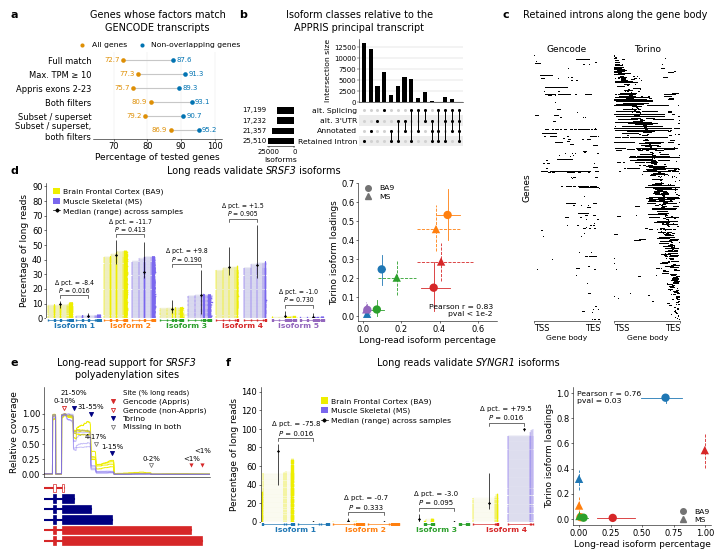

In [9]:
OUT = '../notebooks/Figure2/Figure2_publication'

fig = build_figure()
fig.savefig(OUT + '.png', dpi=400)
fig.savefig(OUT + '.pdf')

# Inkscape-editable text. The PDF backend positions text glyph by glyph, so
# Inkscape imports each label with a per-character x list; deleting or adding
# a letter leaves the rest sitting on their old coordinates, which is why the
# characters pile up. `svg.fonttype='none'` writes each label as one <text>
# element with a font-family and no per-glyph placement, so it edits normally.
# Use the SVG for Inkscape and keep the PDF for submission.
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig.savefig(OUT + '.svg')

print(f'page: {PAGE_W:.1f} x {PAGE_H:.1f} mm')